In [1]:
# ==============================================================
# PREVISÃO DE DISTRATO - MODELO XGBOOST OTIMIZADO
# ==============================================================
# Autor: Fabricio Vargas
# Descrição:
#   Pipeline completo para:
#     1. Extração de dados via SQL Server
#     2. Limpeza, transformação e pivoteamento
#     3. Treinamento e otimização de modelo XGBoost
#     4. Geração e exportação de previsões
# ==============================================================

import warnings
import pyodbc
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier, plot_importance

from tkinter.filedialog import asksaveasfilename
from tkinter import Tk

warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)

In [2]:

def connect_to_db_Melnick():
    try:
        conn_sqlserver = pyodbc.connect(
            'Driver={SQL Server};'
            'Server=SRSBDOTTOPRD01;'
            'Database=Melnick;'
            'uid=sa;'
            r'pwd=)a:8\H\g@YyY$19e3<'
        )
        return conn_sqlserver
    except Exception as e:
        print("Erro ao conectar ao banco de dados:", e)
        return None


In [3]:

conn = connect_to_db_Melnick()  # retorna a conexão já pronta

# ==============================
# 1. Ler tabelas completas via pandas (SQL Server)
# ==============================
df1 = pd.read_sql(r"""
WITH resultado AS (
SELECT *
FROM OPENQUERY([CuboTabular_ReceitaNPL], '
    DEFINE
        VAR DataCorte = EOMONTH(TODAY(), 0)  // último dia do mês atual; use -12 se quiser 12 meses atrás

    EVALUATE
    SUMMARIZECOLUMNS (
        ''Fato Receita Data Base''[cdContrato],
        ''Fato Receita Data Base''[cdCliente],
        ''DIM_Clientes''[dtDataNascimentoCliente],
        ''Fato Receita Data Base''[SituacaoContratoVenda],
        //''Fato Receita Data Base''[DsClassificacao],
        ''Fato Receita Data Base''[Ds Tipo Serie],
        ''Fato Receita Data Base''[dsTipoFinanciamento],
        ''Fato Receita Data Base''[Dt_dtHabiteSe],
        ''Fato Receita Data Base''[Dt_dtVenda],
        ''Fato Receita Data Base''[dtAssinatura],
        //''Fato Receita Data Base''[Dt_dtVencimento],
        ''Fato Receita Data Base''[dtDataBase],
        ''Fato Receita Data Base''[skContrato],
        // Filtro >= DataCorte aplicado corretamente como "filter table"
        FILTER(
            ALL( ''Fato Receita Data Base''[dtDataBase] ),
            ''Fato Receita Data Base''[dtDataBase] = DataCorte
        ),

        "Vl Valor Presente CONTABIL", [Vl Valor Presente CONTABIL]
    )
    ORDER BY
        ''Fato Receita Data Base''[cdContrato]
')
)
SELECT
"Fato Receita Data Base[cdContrato]"             AS CdContrato,
"Fato Receita Data Base[skContrato]"			 AS SkContrato,
"Fato Receita Data Base[cdCliente]"              AS CdCliente,
"DIM_Clientes[dtDataNascimentoCliente]" AS DtNascimentoCliente,
"Fato Receita Data Base[SituacaoContratoVenda]" as pago,
--"Fato Receita Data Base[DsClassificacao]"        AS DsClassificacao,
"Fato Receita Data Base[Ds Tipo Serie]"          AS DsTipoSerie,
"Fato Receita Data Base[dsTipoFinanciamento]"    AS DsTipoFinanciamento,
CONVERT(DATE,"Fato Receita Data Base[Dt_dtHabiteSe]")   AS DtHabiteSe,
CONVERT(DATE,"Fato Receita Data Base[Dt_dtVenda]")      AS DtVenda,
CONVERT(DATE,"Fato Receita Data Base[dtAssinatura]")      AS dtAssinatura,
--CONVERT(DATE,"Fato Receita Data Base[Dt_dtVencimento]") AS DtVencimento,
CONVERT(float,"[Vl Valor Presente CONTABIL]")           AS VlValorPresenteContabil
FROM resultado
""", conn)
conn.close()
print(df1.head())

                CdContrato  SkContrato       CdCliente DtNascimentoCliente       pago DsTipoSerie DsTipoFinanciamento  DtHabiteSe     DtVenda dtAssinatura  VlValorPresenteContabil
0  0602.6020.001.0201.CV01      475668  10642615000175                None  Com Saldo       ANUAL              Direto  2027-08-31  2025-06-29   2025-06-25             1.055454e+07
1  0602.6020.001.0201.CV01      475668  10642615000175                None  Com Saldo         ATO              Direto  2027-08-31  2025-06-29   2025-06-25             2.500000e+05
2  0602.6020.001.0201.CV01      475668  10642615000175                None  Com Saldo       UNICA              Direto  2027-08-31  2025-06-29   2025-06-25             4.912298e+06
3  0602.6020.001.0202.CR02      478426  10642615000175                None  Com Saldo       ANUAL              Direto  2027-08-31  2025-06-29   2025-06-25             1.055454e+07
4  0602.6020.001.0202.CR02      478426  10642615000175                None  Com Saldo       UNICA   

In [4]:

######## PIVOTEAMENTO ########
df_pivot1 = (
    df1.pivot_table(
        index=['CdContrato', 'CdCliente','pago', 'DtHabiteSe', 'DtVenda', 'SkContrato','DsTipoFinanciamento','DtNascimentoCliente'],
        columns=['DsTipoSerie'],
        values='VlValorPresenteContabil',
        aggfunc='sum',
        fill_value=0
    ).reset_index()
)

# Cria a coluna "ATO" como soma das colunas desejadas (se existirem)
cols_ato = ['ATO', 'CARTÃO CRÉDITO', 'SINAL', 'TRF.CREDITO','UNICA']
cols_existentes = [c for c in cols_ato if c in df_pivot1.columns]
cols2 = ['FGTS', 'FINANCIAMENTO', 'DIFERENÇA FI']
if cols_existentes:
    df_pivot1['ATO'] = df_pivot1[cols_existentes].sum(axis=1)

cols2 = ['FGTS', 'FINANCIAMENTO', 'DIFERENÇA FI']
cols_existentes = [c for c in cols2 if c in df_pivot1.columns]
if cols_existentes:
    df_pivot1['FINANCIAMENTO'] = df_pivot1[cols_existentes].sum(axis=1)

cols_ato = [ 'CARTÃO CRÉDITO', 'SINAL', 'TRF.CREDITO','Distratos']
df_pivot1.drop(columns=[c for c in cols_ato if c in df_pivot1.columns], inplace=True, errors='ignore')
# df_pivot1.columns.name = None
df_pivot1['chave'] = (
    df_pivot1['CdContrato'].astype(str)
    + df_pivot1['CdCliente'].astype(str)
)
df_pivot1.drop(columns=['CHEQUE ADM','DAÇÃO','HABITE-SE','INTERMEDIARIA','ITBI','SEMESTRAL', 'CONTRA ESCRIT.', 'DESCONTO', 'DIFERENÇA FI', 'FGTS',
    'JUROS DE OBRA', 'MENSAL', 'MENSAL PÓS', 'P. 30/60/90/120',
    'PERMUTA', 'PRÓ SOLUTO', 'PRÓ SOLUTO AN', 'PRÓ SOLUTO UN', 'RESIDUAL',
    'SEGURO AF', 'SINAL AUTO', 'TRIMESTRAL',''], errors='ignore',inplace=True)
print(df_pivot1.head()) 

DsTipoSerie               CdContrato    CdCliente       pago  DtHabiteSe     DtVenda  SkContrato DsTipoFinanciamento  DtNascimentoCliente  ANUAL         ATO  FINANCIAMENTO       UNICA                               chave
0            0602.6020.001.0501.CP01  50231642091  Com Saldo  2027-08-31  2025-10-16      487748              Direto  1945-07-23 00:00:00    0.0        0.00            0.0        0.00  0602.6020.001.0501.CP0150231642091
1            0602.6020.001.0501.CR02  50231642091  Com Saldo  2027-08-31  2024-06-30      420438              Direto  1945-07-23 00:00:00    0.0  3000000.00            0.0  3000000.00  0602.6020.001.0501.CR0250231642091
2            0602.6020.001.0501.CR03  50231642091  Com Saldo  2027-08-31  2024-06-30      442558              Direto  1945-07-23 00:00:00    0.0        0.00            0.0        0.00  0602.6020.001.0501.CR0350231642091
3            0602.6020.001.0501.CR04  50231642091  Com Saldo  2027-08-31  2024-06-30      461315              Direto  19

In [5]:
conn = connect_to_db_Melnick()  # retorna a conexão já pronta
df3 = pd.read_sql(r"""

WITH FATOVendaContratada AS (
    SELECT *
    FROM OPENQUERY([CuboTabular_ReceitaNPL], '

EVALUATE
SELECTCOLUMNS (
    SUMMARIZECOLUMNS (
        ''FATO Venda Contratada''[cdVendaDistrato],
        ''FATO Venda Contratada''[dtContabilizacao],
        ''FATO Venda Contratada''[nmImobiliaria],
        ''FATO Venda Contratada''[pctPerdaVPL],
        //''FATO Venda Contratada''[PnvVplUndF_vlTAb0_VPL],
        //''FATO Venda Contratada''[PnvVprVPL_vlPropostaVPL],
        ''FATO Venda Contratada''[qtAreaPrivativa],
        ''FATO Venda Contratada''[skContrato],
        ''FATO Venda Contratada''[skImobiliaria],
        ''FATO Venda Contratada''[skTorre],
        ''FATO Venda Contratada''[skUnidade],
        ''FATO Venda Contratada''[vlComissao],
        ''FATO Venda Contratada''[vlPrecoxAreaPrivativaLiquido]

    ),
    /* formatamos a coluna problemática e damos aliases limpos aqui */
    "cdVendaDistrato", ''FATO Venda Contratada''[cdVendaDistrato],
    "dtContabilizacao", ''FATO Venda Contratada''[dtContabilizacao],
    "pctPerdaVPL", ''FATO Venda Contratada''[pctPerdaVPL],
    //"PnvVplUndF_vlTAb0_VPL", ''FATO Venda Contratada''[PnvVplUndF_vlTAb0_VPL],
    //"PnvVprVPL_vlPropostaVPL", ''FATO Venda Contratada''[PnvVprVPL_vlPropostaVPL],
    "qtAreaPrivativa", ''FATO Venda Contratada''[qtAreaPrivativa],
    "skContrato", ''FATO Venda Contratada''[skContrato],
    "vlComissao", ''FATO Venda Contratada''[vlComissao],
    "vlPrecoxAreaPrivativaLiquido", ''FATO Venda Contratada''[vlPrecoxAreaPrivativaLiquido]

)
ORDER BY [dtContabilizacao] DESC

'))

SELECT
    "[skContrato]"                      AS SkContrato,
    "[cdVendaDistrato]"                 AS cdVendaDistrato,
    CONVERT( DATE,"[dtContabilizacao]") AS dtContabilizacao,
    "[pctPerdaVPL]"                     AS pctPerdaVPL,
    --"[PnvVplUndF_vlTAb0_VPL]"         AS PnvVplUndF_vlTAb0_VPL,
    --"[PnvVprVPL_vlPropostaVPL]"       AS PnvVprVPL_vlPropostaVPL,  
    "[qtAreaPrivativa]"                 AS qtAreaPrivativa,
    --"[skImobiliaria]"                 AS skImobiliaria,
    --"[skTorre]"                       AS skTorre,
    --"[skUnidade]"                     AS skUnidade,
    "[vlComissao]"                      AS vlComissao,
    "[vlPrecoxAreaPrivativaLiquido]"    AS vlPrecoxAreaPrivativaLiquido

FROM FATOVendaContratada
--WHERE CONVERT(VARCHAR,"[cdVendaDistrato]") = 'V' -- AND CONVERT(VARCHAR,"[skContrato]") = '478426'

ORDER BY "[dtContabilizacao]" DESC, skContrato DESC
offset 0 rows
""", conn)  
print(df3.head())
conn.close()    

   SkContrato cdVendaDistrato dtContabilizacao  pctPerdaVPL  qtAreaPrivativa  vlComissao  vlPrecoxAreaPrivativaLiquido
0      497762               V       2026-01-02          NaN            85.66        0.00                     1200.2802
1      497769               V       2025-12-30      -0.5772            33.59    13469.17                     7618.7571
2      497767               V       2025-12-30      -0.5535            29.80        0.06                     8199.1369
3      497765               V       2025-12-30      -0.5536            29.80        0.00                     8112.8312
4      497759               V       2025-12-30      -0.0131            19.55    23334.00                    18699.0281


In [6]:
conn = connect_to_db_Melnick()  # retorna a conexão já pronta   
df4 = pd.read_sql(r"""
WITH resultado AS (
    SELECT *
    FROM OPENQUERY([CuboTabular_Controladoria], '
        EVALUATE
        SUMMARIZECOLUMNS(
            ''DIM_Contrato''[cdCliente],
            ''DIM_Contrato''[cdContrato],
            ''DIM_Contrato''[CdSituacaoContrato],
            ''FATO_Venda_Contratada''[Fl_DataBaseAtual],
            ''DIM_Contrato''[skContrato],
            ''DIM_Contrato''[cdContratoVenda],
            ''FATO_Venda_Contratada''[fl_Vaga],
            ''FATO_Venda_Contratada''[qtAreaPrivativa],
            ''FATO_Venda_Contratada''[vlVendaOriginal],

            // 🔹 Filtro de distrato
            KEEPFILTERS(
                TREATAS(
                    {"V"},
                    ''FATO_Venda_Contratada''[cdVendaDistrato]
                )
            ),
            KEEPFILTERS( TREATAS( {1}, FATO_Venda_Contratada[Fl_DataBaseAtual] )),
            
            // 🔹 Filtro: contrato não nulo
            FILTER(
                ALL(''DIM_Contrato''[cdContrato]),
                NOT ISBLANK(''DIM_Contrato''[cdContrato])
            ),

            "vl Venda", [vl Venda]
        )
        ORDER BY
            ''DIM_Contrato''[cdContratoVenda]
    ')
)
SELECT
    "DIM_Contrato[cdCliente]"             AS CdCliente,

    "DIM_Contrato[cdContrato]"            AS CdContrato,
    "DIM_Contrato[CdSituacaoContrato]" AS CdSituacaoContrato,
    "DIM_Contrato[skContrato]"             AS SkContrato,
    "DIM_Contrato[cdContratoVenda]"       AS CdContratoVenda,
    "FATO_Venda_Contratada[fl_Vaga]"     AS FlVaga,
    "FATO_Venda_Contratada[qtAreaPrivativa]" AS QtAreaPrivativa,
    "FATO_Venda_Contratada[vlVendaOriginal]" AS VlVendaOriginal,
    "[vl Venda]"                            AS VlVenda
FROM resultado;""",conn )

print(df4.head())
conn.close()    

Empty DataFrame
Columns: [CdCliente, CdContrato, CdSituacaoContrato, SkContrato, CdContratoVenda, FlVaga, QtAreaPrivativa, VlVendaOriginal, VlVenda]
Index: []


In [7]:
# print(df4[df4['CdContrato'].str.contains('0703.7030.001.0010.CV01', na=False)])

In [8]:
conn = connect_to_db_Melnick()  # retorna a conexão já pronta

df5 = pd.read_sql(r"""
SELECT
*
FROM OPENQUERY([CuboTabular_SAP_FI], 
'EVALUATE
SUMMARIZECOLUMNS(
    ''DIM_Empreendimento''[cdEmpreendimento],
	''DIM_Empreendimento''[nmEmpreendimento])

	')
""", conn)

df5 = df5.rename(columns={"DIM_Empreendimento[cdEmpreendimento]": "Empreendimento"})
print(df5.head())
conn.close()

   Empreendimento DIM_Empreendimento[nmEmpreendimento]
0             175                       NAO CADASTRADO
1             200         EVEN CONSTRUTORA (Matriz/SP)
2             201                 EDIFICIO PIAZZA DOLL
3             202                EDIFICIO CLASSIC WORK
4             203            EDIFICIO TORRE DE FIRENZE


In [9]:
conn = connect_to_db_Melnick()  # retorna a conexão já pronta

df6 = pd.read_sql(r"""
SELECT
*
FROM Empresas_Controladoria


""", conn)

# df6 = df6.rename(columns={"DIM_Empreendimento[cdEmpreendimento]": "Empreendimento"})
print(df6.head())

  cd_empresa grupo_economico_n2                 n3_ajust                  nivel_3
0       0601       Incorporação  Melnick Desenvolvimento  Melnick Desenvolvimento
1       0602       Incorporação  Melnick Desenvolvimento  Melnick Desenvolvimento
2       0603       Incorporação  Melnick Desenvolvimento  Melnick Desenvolvimento
3       0604       Incorporação  Melnick Desenvolvimento  Melnick Desenvolvimento
4       0605       Incorporação  Melnick Desenvolvimento  Melnick Desenvolvimento


In [10]:
df_final = (
    df_pivot1
    .merge(df3, on='SkContrato', how='left', suffixes=('_left', '_right'))
    .merge(df4, on='SkContrato', how='left', suffixes=('', '_dim'))
    # .merge(df_pivot4, on='CdContrato', how='left')

)


In [18]:
df_raw = df_final
# print(df_raw[df_raw['SkContrato'].str.contains('166799', na=False)])
# print(df_raw[df_raw['SkContrato'] == 166799])
# print(df_raw.head())
print(df_raw.info  )

<bound method DataFrame.info of                     CdContrato    CdCliente       pago  DtHabiteSe     DtVenda  SkContrato DsTipoFinanciamento  DtNascimentoCliente  ANUAL         ATO  FINANCIAMENTO       UNICA                               chave cdVendaDistrato dtContabilizacao  pctPerdaVPL  qtAreaPrivativa  vlComissao  vlPrecoxAreaPrivativaLiquido CdCliente_dim CdContrato_dim CdSituacaoContrato CdContratoVenda FlVaga QtAreaPrivativa VlVendaOriginal VlVenda
0      0602.6020.001.0501.CP01  50231642091  Com Saldo  2027-08-31  2025-10-16      487748              Direto  1945-07-23 00:00:00    0.0        0.00            0.0        0.00  0602.6020.001.0501.CP0150231642091               V       2025-10-16          NaN            518.9        0.00                      762.7981           NaN            NaN                NaN             NaN    NaN             NaN             NaN     NaN
1      0602.6020.001.0501.CR02  50231642091  Com Saldo  2027-08-31  2024-06-30      420438              Dire

In [23]:
# ==============================================================
# 4. Limpeza e criação de features
# ==============================================================
def clean_and_engineer_features(df):
    """Limpa colunas, trata datas e cria variáveis derivadas."""

    df = df[~df['CdCliente'].astype(str).str.contains('-', na=False)]
    # df = df[~df['CdEstadoCivilCliente'].astype(str).str.contains('-', na=False)]
    # df = df[df['PnvVprVPL_vlPropostaVPL']!= 0]
    # df['%pago'] = (df['Pago'] / df['PnvVprVPL_vlPropostaVPL']).astype(float)    
    df['CdContrato2'] = df['CdContrato'].astype(str).str[19:21]
    df['chave'] = df['CdContrato'].astype(str).str.slice(0, 18) + df['CdCliente'].astype(str)
    df['Empreendimento'] = df['CdContrato'].astype(str).str[5:9].astype(int)
    df['cd_empresa'] =  df['CdContrato'].astype(str).str[0:4]
    # print(df.head())

    df = (
    df
    .merge(df6, on='cd_empresa', how='left', suffixes=('_left', '_right')))

    # )
    # Cria um dicionário de contrato → data do distrato (a mais recente, se houver mais de um)
    # mapa_distrato = (
    #     df.loc[df['cdVendaDistrato'] == 'D', ['CdContrato', 'dtContabilizacao']]
    #     .sort_values('dtContabilizacao')
    #     .drop_duplicates(subset='CdContrato', keep='last')
    #     .set_index('CdContrato')['dtContabilizacao']
    #     .to_dict()
    # )

    # # Cria a nova coluna dtDistrato somente para as linhas de VENDA ('V')
    # df['dtDistrato'] = np.where(
    #     df['cdVendaDistrato'] == 'V',
    #     df['CdContrato'].map(mapa_distrato),  # pega data de distrato se existir
    #     pd.NaT                                  # mantém vazio para os demais
    # )

        # Contagem por chave
    contagem = (
        df[df['CdContrato2'].isin(['CR'])]
        .groupby(['chave', 'CdContrato2'])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )
    df = df.merge(contagem, on='chave', how='left')

    # Conversão de datas
    for c in [ 'DtVenda','DtHabiteSe','DtNascimentoCliente']:
        df[c] = pd.to_datetime(df[c], errors='coerce')

    df['ano_venda'] = df['DtVenda'].dt.year
    df['mes_venda'] = df['DtVenda'].dt.month
    df['trimestre_venda'] = df['DtVenda'].dt.quarter
    df['semana_venda'] = df['DtVenda'].dt.isocalendar().week



    # Features temporais
    df['Dias_Venda_HabiteSe'] = ( df['DtHabiteSe'] - df['DtVenda'] ).dt.days
    # df['Dias_HabiteSe_DataBase'] = (df['DtHabiteSe'] - df['DtDataBase']).dt.days
    # Se houver dtContab_D_em_V, usa DtHabiteSe - dtContab_D_em_V; senão mantém a diferença com DtVenda
    # df['Dias_venda_distrato'] = df['aa']
    # mask = df['dtDistrato'].notna()
    # df.loc[mask, 'Dias_venda_distrato'] = (
    #       df.loc[mask, 'dtDistrato'] - df.loc[mask, 'DtVenda']
    # ).dt.days
    
    # df['Dias_Assinatura_Validacao'] = (df['DtValidacao'] - df['DtAssinatura']).dt.days
    df['idade_cliente'] = ((df['DtVenda'] - df['DtNascimentoCliente']).dt.days // 365)

    # Label de distrato
    df['tem_D'] = df.groupby('SkContrato')['cdVendaDistrato'].transform(lambda x: 1 if 'D' in x.values else 0)
    df = df[df['cdVendaDistrato'] != 'D']
    # df['PagoTotal'] = df['chave'].map(df.groupby('chave')['Pago'].sum())
    df['ptc_ATO'] = (df['ATO'] / df['VlVendaOriginal']).astype(float)
    # df['PTC_FINANCIAMENTO'] = (df['FINANCIAMENTO'] / df['VlVendaOriginal']).astype(float)   
    # # df['vl_restante'] = (df['VlVendaOriginal'] - df['Pago']).astype(float)
    # df['vl_restante'] = np.where(
    # (df['VlVendaOriginal'] - df['PagoTotal']).astype(float) < 0,
    # 0,
    # (df['VlVendaOriginal'] - df['PagoTotal']).astype(float)
    # )
    # # df['vl_restante_pct'] = (1 - df['vl_pago_pct']).astype(float)
    # df['vl_restante_pct'] = np.where( (1 - df['vl_pago_pct']).astype(float) <0,0,
    #                              (1 - df['vl_pago_pct']).astype(float))    

    taxa_distrato = df.groupby('Empreendimento')['tem_D'].mean()
    df['taxa_distrato_empreendimento'] = (df['Empreendimento'].map(taxa_distrato)).astype(float)
    df['VlVendaOriginal'] = df.apply(
    lambda x: x['vlPrecoxAreaPrivativaLiquido'] * x['qtAreaPrivativa']
    if pd.isna(x['VlVendaOriginal']) or x['VlVendaOriginal'] == 0
    else x['VlVendaOriginal'],
    axis=1
    )
    # Filtro e drop de colunas ,'CR','DtNascimentoCliente' 
    df = df[df['CdContrato2'] == 'CV']
    df = df[df['FlVaga'] == 0]  
    df = df[df['nivel_3'] == 'Melnick Desenvolvimento']
    cols_drop = [ 
        'chave', 'CdCliente','NrProposta','DtHabiteSe','CdContrato_dim','CdCliente_dim','DsSituacaoContrato','CdContrato2',
        'NrUnidade','DtAssinatura','DtValidacao','emp','vlDevolvido','Em Dia','QtAreaPrivativa',
        'TRIMESTRAL','RESIDUAL','PERMUTA','PRÓ SOLUTO AN','PRÓ SOLUTO UN','PERMUTA', 'JUROS DE OBRA',
        'Distratos','PRÓ SOLUTO','FGTS','dtContabilizacao','DIFERENÇA FI', 'DtDataBase', 'SkContrato',
        'NrUnidade','SEGURO AF', 'MENSAL PÓS','DESCONTO', '-','CdSituacaoContrato','VlVenda','CdContratoVenda',
        'TRF.CREDITO','SINAL AUTO','Vencido','cdVendaDistrato','CHEQUE ADM','DACAO','Pago','n3_ajust',
        'grupo_economico_n2','FlVaga','cd_empresa','nivel_3','FINANCIAMENTO','DtNascimentoCliente','aa'
    ]

    df.drop(columns=[c for c in cols_drop if c in df.columns], inplace=True, errors='ignore')

    cols = ['CR','Total','pctPerdaVPL'
     'pctPerdaNominal','idade_cliente']
    for col in cols:
        if col in df.columns:
            df[col] = df[col].fillna(0)


    for col in df.select_dtypes(include='number').columns:
        df[col] = df[col].fillna(0).astype(float)

    # df = df.dropna()
    return df
df_clean = clean_and_engineer_features(df_raw)

In [24]:

print(df_clean.info)
# print(df_clean[df_clean['CdContrato'].str.contains('0705.7052.015.0009.CV01', na=False)])

<bound method DataFrame.info of Empty DataFrame
Columns: [CdContrato, pago, DtVenda, DsTipoFinanciamento, ANUAL, ATO, UNICA, pctPerdaVPL, qtAreaPrivativa, vlComissao, vlPrecoxAreaPrivativaLiquido, VlVendaOriginal, Empreendimento, CR, ano_venda, mes_venda, trimestre_venda, semana_venda, Dias_Venda_HabiteSe, idade_cliente, tem_D, ptc_ATO, taxa_distrato_empreendimento]
Index: []>


In [17]:
print(df_clean['tem_D'].value_counts()
)
print(df_clean['pago'].value_counts()
)

Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)


In [19]:
# percentuais_nulos = (
#     df_clean.isnull().mean()
#     .mul(100)
#     .round(2)
#     .sort_values(ascending=False)
#     .reset_index()
# )
# print(percentuais_nulos)

In [20]:

# define o limite (hoje - 2 anos)
limite = pd.Timestamp.today() - pd.DateOffset(years=1)
# define limite de 2025 em diante
# limite_2025 = pd.Timestamp('2025-01-01')
# print("Limite de data para treino/teste:", limite, '\n')
# filtra linhas com DtVenda <= limite
df_treino = df_clean[df_clean['DtVenda'] <= limite]
# df_treino = df_treino[df_treino['DtVenda'] >= limite_2025]

df_projecao = df_clean[df_clean['DtVenda'] > limite]
# remove distratos do conjunto de projeção
df_projecao = df_projecao[df_projecao['tem_D'] != 1]

treinoquitado = df_projecao[df_projecao['pago'] == 'Quitado']
df_projecao = df_projecao[df_projecao['pago'] != 'Quitado']
df_projecao = (
df_projecao
.merge(df5, on='Empreendimento', how='left', suffixes=('_left', '_right')))
df_projecao = df_projecao.drop(columns=['pago'])  
# adiciona ao treino todos os distratos do período recente
df_treino_extra = df_clean[(df_clean['DtVenda'] > limite) & (df_clean['tem_D'] == 1) & (df_clean['pago'] != 'Quitado')]
# print(df_treino_extra.head())
df_treino = pd.concat([df_treino, df_treino_extra], ignore_index=True)


In [30]:
print(df_projecao.sample(15))

                  CdContrato  DsTipoFinanciamento          ANUAL           ATO         UNICA  pctPerdaVPL  qtAreaPrivativa  vlComissao  vlPrecoxAreaPrivativaLiquido  VlVendaOriginal  Empreendimento   CR  ano_venda  mes_venda  trimestre_venda  semana_venda  Dias_Venda_HabiteSe  idade_cliente  tem_D   ptc_ATO  taxa_distrato_empreendimento               DIM_Empreendimento[nmEmpreendimento]  Prob_Distrato  Prev_Distrato
421  0789.7890.004.0722.CV01                    5   48142.139779  3.824292e+04  3.518292e+04       0.0153            19.55    18460.96                    17941.6020        350758.32          7890.0  0.0     2025.0       11.0              4.0          48.0               1282.0           63.0    0.0  0.109029                      0.000000  Melnick Even Sagittarius Empreendimento Imobil...       0.000563              0
626  0834.8342.004.0108.CV01                    3       0.000000  5.000000e+02  0.000000e+00       0.0475            41.84        0.00                     6092.

In [22]:
def encode_categoricals(df, verbose=True):
    """
    Converte todas as colunas não numéricas em códigos numéricos (Label Encoding).
    """
    df = df.copy()
        # Drop de colunas  , 'CdContrato', 'DtVenda'
    cols_drop = [ 
        'CdContrato', 'DtVenda','pago'
    ]
    df.drop(columns=[c for c in cols_drop if c in df.columns], inplace=True, errors='ignore')
    encoders = {}
    cat_cols = df.select_dtypes(include=['object', 'string', 'category']).columns

    for col in cat_cols:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str).fillna('NaN'))
        encoders[col] = le


    if verbose:
        print(f"Colunas convertidas ({len(cat_cols)}): {list(cat_cols)}")
    return df, encoders


df, encoders = encode_categoricals(df_treino, verbose=True)

Colunas convertidas (1): ['DsTipoFinanciamento']


In [23]:
def apply_encoders(df, encoders):
    """
    Aplica encoders salvos a um novo DataFrame.
    - Garante que valores não vistos sejam tratados como 'NaN'.
    - Adiciona 'NaN' às classes do encoder, se ainda não existir.
    """
    df = df.copy()

    for col, le in encoders.items():
        if col in df.columns and col != 'CdContrato':  # evita codificar o identificador
            df[col] = df[col].astype(str).fillna('NaN')

            # Adiciona 'NaN' à lista de classes, se necessário
            if 'NaN' not in le.classes_:
                le.classes_ = np.append(le.classes_, 'NaN')

            # Substitui categorias novas por 'NaN'
            df[col] = df[col].apply(lambda x: x if x in le.classes_ else 'NaN')

            # Faz a transformação segura
            df[col] = le.transform(df[col])

    return df
df_projecao = apply_encoders(df_projecao, encoders)
# temD = df_projecao[['tem_D','CdContrato']]
df_projecao.drop(columns=['DtVenda'], errors='ignore',inplace=True)

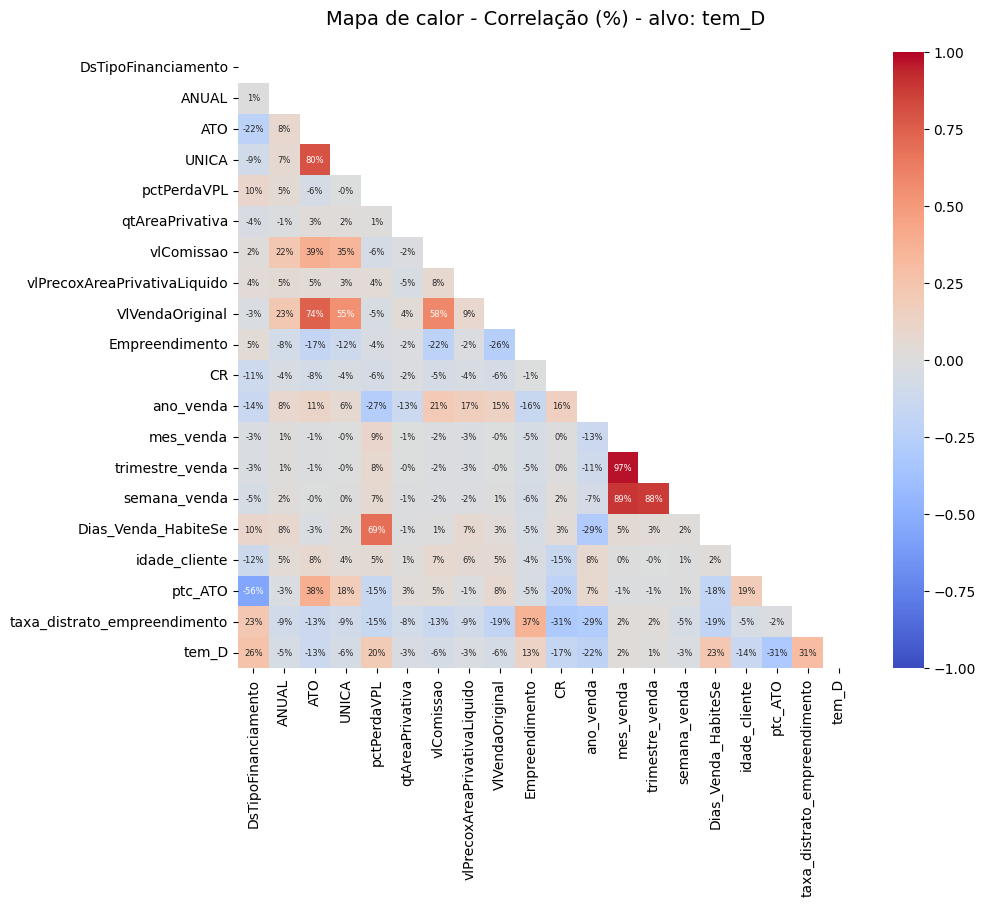

In [24]:
def plot_correlation_heatmap(df: pd.DataFrame, target: str, annot_size: int):
    corr = df.corr(numeric_only=True)

    # move a variável alvo para a última linha e coluna
    cols = [c for c in corr.columns if c != target] + [target]
    corr = corr.loc[cols, cols]

    mask = np.triu(np.ones_like(corr, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".0%",
        cmap="coolwarm",
        vmin=-1, vmax=1,
        cbar=True,
        square=True,
        annot_kws={"size": annot_size}
    )
    plt.title(f"Mapa de calor - Correlação (%) - alvo: {target}", fontsize=14, pad=20)
    plt.show()

# exemplo de uso
plot_correlation_heatmap(df, target='tem_D', annot_size=6)


In [25]:
# ============================================
# PREVISÃO DE DISTRATO - MODELO XGBOOST OTIMIZADO
# ============================================



# ============================================
# 1. Carregamento e preparação dos dados
# ============================================

# Exemplo: se teu DataFrame já estiver carregado como `df`
# df = pd.read_csv('dados_distrato.csv')

# Mantendo as colunas CdEmpreendimento, NrUnidade, nmImobiliaria (convertidas para numérico)
# Drop apenas colunas que realmente não fazem sentido (IDs, duplicadas, etc.)

target = 'tem_D'
# df = df.dropna(axis=1)
X = df.drop(target, axis=1)
y = df[target]


# Separar variáveis numéricas e categóricas
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
# cat_cols = X.select_dtypes(include=['object']).columns

# ============================================
# 2. Split treino/teste + SMOTE
# ============================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Balanceamento
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# ============================================
# 3. Pré-processamento
# ============================================
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols)
])

# ============================================
# 4. Definição do modelo base
# ============================================
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    use_label_encoder=False,
    random_state=42,
    n_jobs=-1
)

# ============================================
# 5. Grade de hiperparâmetros
# ============================================
param_grid = { 'clf__max_depth': [3, 5, 7, 9],
               'clf__n_estimators': [200],
                 'clf__learning_rate': [0.01, 0.03, 0.05, 0.1],
                   'clf__subsample': [0.8], 
                   'clf__colsample_bytree': [0.8],
                     'clf__scale_pos_weight': [2.5, 3] }


# ============================================
# 6. Pipeline completo
# ============================================
pipe = Pipeline([
    ('prep', preprocess),
    ('clf', xgb)
])

# ============================================
# 7. Otimização com GridSearchCV
# ============================================
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=2
)


grid.fit(X_train_res, y_train_res)

print("🔍 Melhor combinação de hiperparâmetros:")
print(grid.best_params_)
print("Melhor AUC (cross-val):", grid.best_score_)

# ============================================
# 8. Avaliação no conjunto de teste
# ============================================
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]





Fitting 3 folds for each of 32 candidates, totalling 96 fits
🔍 Melhor combinação de hiperparâmetros:
{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.1, 'clf__max_depth': 9, 'clf__n_estimators': 200, 'clf__scale_pos_weight': 2.5, 'clf__subsample': 0.8}
Melhor AUC (cross-val): 0.9752712988166768


## 🔍 Avaliação de Métricas do Modelo

📊 Classification Report:
              precision    recall  f1-score   support

         0.0       0.93      0.90      0.91      1974
         1.0       0.76      0.81      0.78       745

    accuracy                           0.88      2719
   macro avg       0.84      0.86      0.85      2719
weighted avg       0.88      0.88      0.88      2719

Acurácia (Accuracy): 0.88
- Mede a proporção total de acertos do modelo.

Precisão (Precision) [classe 1]: 0.76
- Mede quantos dos casos previstos como positivos realmente eram positivos.

Recall (Sensibilidade) [classe 1]: 0.81
- Mede quantos positivos reais o modelo capturou.

F1-Score [classe 1]: 0.78
- Combina precisão e recall em uma única métrica de equilíbrio.

AUC (Área sob a curva ROC): 0.933
- Mede a capacidade de separar positivos de negativos.



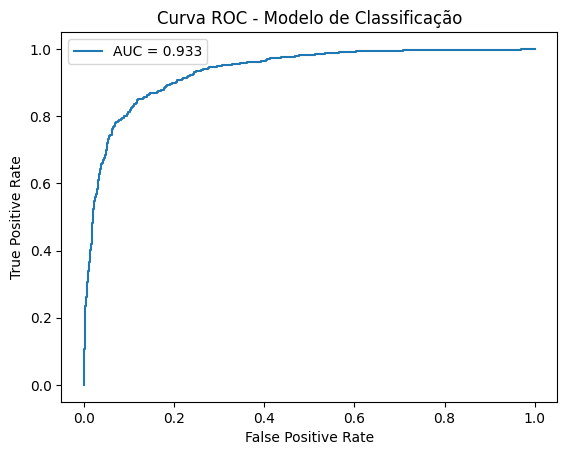

### 📊 Matriz de Confusão:
          Prev_0.0  Prev_1.0
Real_0.0      1782       192
Real_1.0       143       602


<Figure size 1000x700 with 0 Axes>

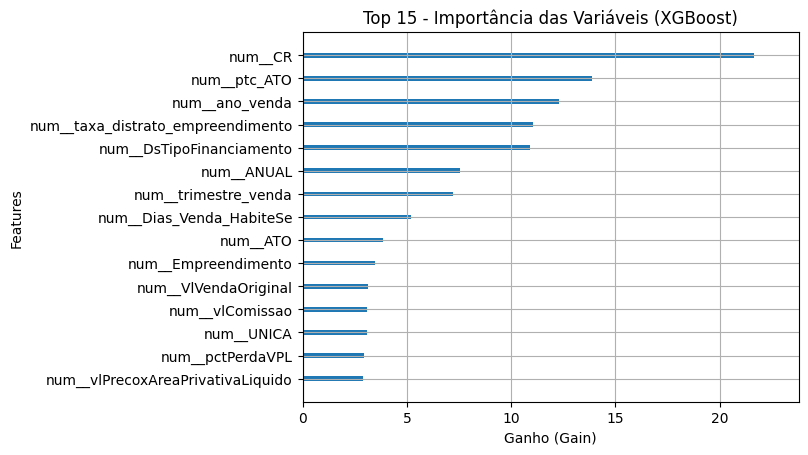

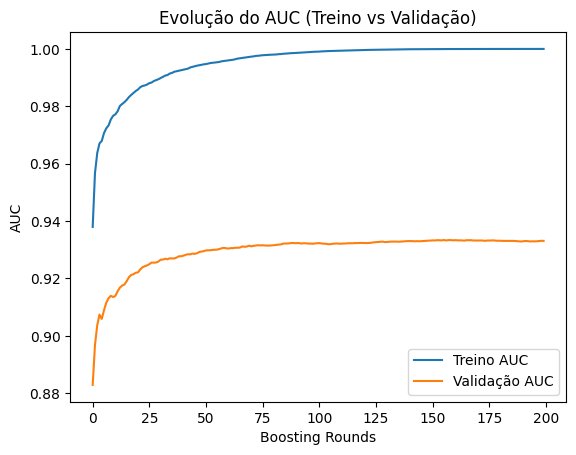


✅ Avaliação concluída.



In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

def exibir_metricas_dinamico(y_true, y_pred, y_prob=None, positive_label=None):
    """
    Exibe as principais métricas de classificação de forma segura e detalhada.
    - Evita KeyError mesmo que o label '1' não exista.
    - Calcula AUC e plota curva ROC se y_prob for informado.
    - Funciona com labels binários, categóricos ou numéricos.

    Parâmetros:
    -----------
    y_true : array-like
        Valores reais da variável alvo.
    y_pred : array-like
        Predições do modelo.
    y_prob : array-like (opcional)
        Probabilidades previstas para a classe positiva.
    positive_label : valor (opcional)
        Define explicitamente qual classe é considerada "positiva".
        Se None, será inferida automaticamente.
    """
    print("## 🔍 Avaliação de Métricas do Modelo\n")
    print("📊 Classification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    # Inferir classe positiva se não especificada
    labels = np.unique(y_true)
    if positive_label is None:
        positive_label = 1 if set(labels) <= {0, 1} else labels[-1]

    # Métricas básicas
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary', pos_label=positive_label, zero_division=0
    )

    print(f"Acurácia (Accuracy): {acc:.2f}")
    print("- Mede a proporção total de acertos do modelo.\n")

    print(f"Precisão (Precision) [classe {positive_label}]: {prec:.2f}")
    print("- Mede quantos dos casos previstos como positivos realmente eram positivos.\n")

    print(f"Recall (Sensibilidade) [classe {positive_label}]: {rec:.2f}")
    print("- Mede quantos positivos reais o modelo capturou.\n")

    print(f"F1-Score [classe {positive_label}]: {f1:.2f}")
    print("- Combina precisão e recall em uma única métrica de equilíbrio.\n")

    # AUC e curva ROC
    if y_prob is not None:
        try:
            auc = roc_auc_score(y_true, y_prob)
            print(f"AUC (Área sob a curva ROC): {auc:.3f}")
            print("- Mede a capacidade de separar positivos de negativos.\n")

            fpr, tpr, _ = roc_curve(y_true, y_prob, pos_label=positive_label)
            plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title('Curva ROC - Modelo de Classificação')
            plt.legend()
            plt.show()
        except ValueError:
            print("⚠️  AUC/ROC não pôde ser calculado (verifique y_prob e classes).")

    # Matriz de confusão
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    print("### 📊 Matriz de Confusão:")
    print(pd.DataFrame(cm, index=[f"Real_{l}" for l in labels],
                             columns=[f"Prev_{l}" for l in labels]))
    # Extrair nomes do ColumnTransformer
    feature_names = best_model.named_steps['prep'].get_feature_names_out(X.columns)

    # Converter para lista pura de strings
    feature_names = feature_names.tolist()

    # Aplicar ao booster
    xgb_model = best_model.named_steps['clf']
    booster = xgb_model.get_booster()
    booster.feature_names = feature_names  # ✅ agora funciona

    # Plotar importância com nomes originais

    plt.figure(figsize=(10, 7))
    plot_importance(
        booster,
        importance_type='gain',
        max_num_features=15,
        xlabel='Ganho (Gain)',
        show_values=False
    )
    plt.title('Top 15 - Importância das Variáveis (XGBoost)')
    plt.show()

    # Extrai o melhor modelo do grid
    best_params = grid.best_params_
    best_xgb = XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        use_label_encoder=False,
        random_state=42,
        **{k.replace('clf__',''): v for k,v in best_params.items()}
    )

    # Reentreina com dados de treino e validação
    eval_set = [(X_train_res, y_train_res), (X_test, y_test)]
    best_xgb.fit(X_train_res, y_train_res, eval_set=eval_set, verbose=False)

    # Agora sim, você pode acessar o histórico
    evals_result = best_xgb.evals_result()

    # Plot AUC treino vs validação
    epochs = len(evals_result['validation_0']['auc'])
    plt.plot(range(epochs), evals_result['validation_0']['auc'], label='Treino AUC')
    plt.plot(range(epochs), evals_result['validation_1']['auc'], label='Validação AUC')
    plt.xlabel('Boosting Rounds')
    plt.ylabel('AUC')
    plt.title('Evolução do AUC (Treino vs Validação)')
    plt.legend()
    plt.show()



    print("\n✅ Avaliação concluída.\n")


# Exemplo de uso:
exibir_metricas_dinamico(y_test, y_pred, y_prob)


In [31]:
# 3. gerar previsões
y_pred_novos = best_model.predict(df_projecao)
y_prob_novos = best_model.predict_proba(df_projecao)[:, 1]

# 4. salvar
df_projecao['Prob_Distrato'] = y_prob_novos
df_projecao['Prev_Distrato'] = y_pred_novos

# df_final = (
#     df_projecao
#     .merge(temD, on='CdContrato', how='left')

# )

# Exportação com caixa de diálogo
root = Tk(); root.withdraw(); root.attributes("-topmost", True)
caminho_exportacao = asksaveasfilename(title="Salvar Excel", defaultextension=".xlsx",
                                        filetypes=[("Arquivo Excel", "*.xlsx")])
root.destroy()

if caminho_exportacao:
    df_projecao.to_excel(caminho_exportacao, index=False)
    print(f"\n✅ Arquivo exportado com sucesso: {caminho_exportacao}")
else:
    print("Exportação cancelada.")


✅ Arquivo exportado com sucesso: C:/Users/fabriciovargas/Melnick/Controladoria Comercial - Tranfer VM/distratos.xlsx
